# Portafolio Cuantitativo Neutral al Mercado

## Backtest Corregido: Contabilidad con Pesos Congelados

**Autor:** Samuel
**Institución:** Tec de Monterrey
**Área:** Finanzas Cuantitativas, Economía Estadística y Machine Learning
**Notebooks previos:** `main.ipynb`, `RMT+TDA.ipynb`, `K-D.ipynb`, `Walk-Forward.ipynb`, `Perfiles-Riesgo.ipynb`

---

La auditoría al final de `Perfiles-Riesgo.ipynb` mostró que el backtest usado desde `K-D.ipynb` sobrestimaba el P&L: ~83-84% del bruto era ganancia fantasma por la recalibración del β, y los costos omitían la pata de la variable dependiente. Este notebook reconstruye el backtest con tres principios:

1. **Pesos congelados:** el portafolio formado en t es (1 unidad de y, −β_{t−1} unidades de cada x) y gana de t a t+1 exactamente Δy − β·ΔX. Actualizar el estimado de β no genera ganancia.
2. **Costos completos:** se cobran sobre todas las patas al cambiar la posición, más el costo de rebalancear pesos mientras se sostiene.
3. **Sin información fuera de muestra:** el HMM se entrena en `train` y se aplica causalmente en `test`.

Con esa contabilidad se responde, ahora sí, qué tan bien funciona el método: ¿el Kalman dinámico mejora a un β estático?, ¿el borde bruto es consistente a través del tiempo?, ¿a partir de qué costo sobrevive?

## Estructura de este Notebook

1. **Instalación de librerías**: las mismas de `K-D.ipynb`.
2. **Fase 1: Datos**: reutilizada (12 divisas, ~729 días por hora, split 70/30).
3. **Fase 2: Re-validación de la canasta**: USDJPY, USDSEK, USDNOK, USDSGD (validada en `RMT+TDA.ipynb`; no se re-descubre, dado el sesgo de Johansen en ventanas cortas encontrado en `Walk-Forward.ipynb`).
4. **Fase 3: Señales**: dos versiones sobre la misma canasta: Kalman dinámico (como `K-D.ipynb`) y un β estático (el último estado de `train`, congelado) como línea base.
5. **Fase 4: Reglas + HMM causal**: entradas/salidas como antes; HMM entrenado en `train`.
6. **Fase 5: Backtest corregido**: función única `run_backtest_frozen`, **prueba de cordura** (el mismo backtest sobre series sintéticas sin relación debe dar bruto ≈ 0; si da positivo, el backtest tiene un sesgo), comparación dinámico vs. estático y sensibilidad a costos.
7. **Fase 6: Walk-forward de 20 ventanas** con la misma contabilidad.
8. **Conclusión.**

In [2]:
# %pip install yfinance pandas numpy scipy statsmodels pykalman hmmlearn matplotlib

## Fase 1: Datos

Mismo universo y ventana de siempre, con una corrección: las columnas se renombran **por ticker, no por posición** (yfinance las devuelve en orden alfabético). Una verificación de niveles de precio detiene la ejecución si algún nombre no corresponde a su dato.

In [3]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy import linalg
from scipy.stats import norm, ttest_1samp, linregress
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from numpy.linalg import lstsq
from pykalman import KalmanFilter
from hmmlearn.hmm import GaussianHMM
from statsmodels.tsa.vector_ar.vecm import coint_johansen
import warnings

In [4]:
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

tickers = {
    'EURUSD': 'EURUSD=X', 'GBPUSD': 'GBPUSD=X', 'AUDUSD': 'AUDUSD=X', 'NZDUSD': 'NZDUSD=X',
    'USDJPY': 'USDJPY=X', 'USDCAD': 'USDCAD=X', 'USDCHF': 'USDCHF=X', 'USDMXN': 'USDMXN=X',
    'USDCNY': 'USDCNY=X', 'USDSEK': 'USDSEK=X', 'USDNOK': 'USDNOK=X', 'USDSGD': 'USDSGD=X',
}

raw_close = yf.download(list(tickers.values()), period='729d', interval='60m', progress=False)['Close']

# Renombrar por NOMBRE de ticker (no por posición) y luego ordenar
ticker_to_name = {v: k for k, v in tickers.items()}
raw_data = raw_close.rename(columns=ticker_to_name)[list(tickers.keys())]

In [5]:
# Verificación de cordura: el nivel de cada serie debe corresponder a su nombre
expected_ranges = {
    'EURUSD': (0.9, 1.4), 'GBPUSD': (1.0, 1.6), 'AUDUSD': (0.5, 0.9), 'NZDUSD': (0.5, 0.8),
    'USDJPY': (100, 170), 'USDCAD': (1.2, 1.5), 'USDCHF': (0.7, 1.1), 'USDMXN': (15, 25),
    'USDCNY': (6.0, 8.0), 'USDSEK': (8, 12), 'USDNOK': (8, 12.5), 'USDSGD': (1.2, 1.5),
}
summary = raw_data.agg(['min', 'mean', 'max']).T
summary['rango_esperado'] = pd.Series(expected_ranges)
summary['ok'] = [expected_ranges[c][0] <= summary.loc[c, 'mean'] <= expected_ranges[c][1] for c in summary.index]
print(summary)
assert summary['ok'].all(), "Alguna columna tiene un nivel de precio que no corresponde a su nombre"

               min        mean         max rango_esperado    ok
Ticker                                                         
EURUSD    1.019576    1.121336    1.204674     (0.9, 1.4)  True
GBPUSD    1.210771    1.311169    1.385003     (1.0, 1.6)  True
AUDUSD    0.595249    0.666859    0.727273     (0.5, 0.9)  True
NZDUSD    0.551177    0.590961    0.637552     (0.5, 0.8)  True
USDJPY  139.850998  152.786283  163.957993     (100, 170)  True
USDCAD    1.323600    1.384647    1.478120     (1.2, 1.5)  True
USDCHF    0.760890    0.839333    0.922250     (0.7, 1.1)  True
USDMXN   16.257999   18.387557   21.266500       (15, 25)  True
USDCNY    6.680200    7.073879    7.349400     (6.0, 8.0)  True
USDSEK    8.766750    9.972097   11.298900        (8, 12)  True
USDNOK    9.149180   10.279780   11.511410      (8, 12.5)  True
USDSGD    1.259680    1.309424    1.374740     (1.2, 1.5)  True


In [6]:
data = raw_data.copy().ffill().dropna()
split_idx = int(len(data) * 0.70)
train, test = data.iloc[:split_idx], data.iloc[split_idx:]
print(f"data: {data.shape} | train: {train.shape} | test: {test.shape}")

data: (17321, 12) | train: (12124, 12) | test: (5197, 12)


In [7]:
data = raw_data.copy().ffill().dropna()
split_idx = int(len(data) * 0.70)
train, test = data.iloc[:split_idx], data.iloc[split_idx:]
print(f"data: {data.shape} | train: {train.shape} | test: {test.shape}")

data: (17321, 12) | train: (12124, 12) | test: (5197, 12)


## Fase 2: Re-validación de la Canasta

Se repite RMT → clustering → Johansen con los nombres correctos. La canasta validada en los notebooks anteriores corresponde, por el mapeo inferido, a **USDCAD, USDNOK, USDSEK, USDSGD**. Aquí se verifica en vez de asumirlo. Como la ventana de 729 días se recorrió desde las corridas anteriores, los resultados pueden diferir un poco.

In [8]:
def clean_correlation_rmt(log_returns):
    N, T = log_returns.shape[1], log_returns.shape[0]
    Q = T / N
    corr = log_returns.corr()
    eigenvalues, eigenvectors = linalg.eigh(corr.values)
    eigenvalues, eigenvectors = eigenvalues[::-1], eigenvectors[:, ::-1]
    lambda_plus = (1 + np.sqrt(1 / Q)) ** 2
    n_signal = (eigenvalues > lambda_plus).sum()
    cleaned = eigenvalues.copy()
    if n_signal < len(eigenvalues):
        cleaned[n_signal:] = eigenvalues[n_signal:].mean()
    corr_clean = eigenvectors @ np.diag(cleaned) @ eigenvectors.T
    d = np.sqrt(np.diag(corr_clean))
    return pd.DataFrame(corr_clean / np.outer(d, d), index=corr.index, columns=corr.columns)


def rmt_clusters(corr_clean, cut_height=1.0):
    dist = np.sqrt(2 * np.clip(1 - corr_clean.values, 0, None))
    dist = (dist + dist.T) / 2
    np.fill_diagonal(dist, 0)
    Z = linkage(squareform(dist, checks=False), method='average')
    labels = fcluster(Z, t=cut_height, criterion='distance')
    df = pd.DataFrame({'divisa': corr_clean.columns, 'cluster': labels})
    return df.groupby('cluster')['divisa'].apply(list).to_dict()


def johansen_n_relations(log_prices, lag):
    r = coint_johansen(log_prices, det_order=0, k_ar_diff=lag)
    return int((r.lr1 > r.cvt[:, 1]).sum())


log_returns_train = np.log(train / train.shift(1)).dropna()
corr_clean = clean_correlation_rmt(log_returns_train)
clusters = rmt_clusters(corr_clean, cut_height=1.0)

for cid, members in clusters.items():
    print(f"Cluster {cid}: {members}")

print("\nJohansen en log-precios, relaciones por rezago (clusters de 3+ divisas):")
for cid, members in clusters.items():
    if len(members) >= 3:
        hits = {lag: johansen_n_relations(np.log(train[members]), lag) for lag in [1, 4, 12, 24, 48]}
        print(f"  Cluster {cid} {members}: {hits}")

Cluster 1: ['EURUSD', 'GBPUSD', 'AUDUSD', 'NZDUSD']
Cluster 2: ['USDJPY', 'USDCHF']
Cluster 3: ['USDCAD', 'USDSEK', 'USDNOK', 'USDSGD']
Cluster 4: ['USDCNY']
Cluster 5: ['USDMXN']

Johansen en log-precios, relaciones por rezago (clusters de 3+ divisas):
  Cluster 1 ['EURUSD', 'GBPUSD', 'AUDUSD', 'NZDUSD']: {1: 0, 4: 0, 12: 0, 24: 0, 48: 0}
  Cluster 3 ['USDCAD', 'USDSEK', 'USDNOK', 'USDSGD']: {1: 1, 4: 1, 12: 1, 24: 1, 48: 1}


In [9]:
FIXED_BASKET = ['USDCAD', 'USDNOK', 'USDSEK', 'USDSGD']
print("¿La canasta coincide con un cluster?:", set(FIXED_BASKET) in [set(m) for m in clusters.values()])

¿La canasta coincide con un cluster?: True


## Fase 3: Señales

Sobre la misma canasta se construyen dos versiones que comparten reglas, z-score y costos; solo difieren en cómo se determinan los pesos del portafolio:

- **Dinámico:** β evoluciona como estado del Kalman (como en `K-D.ipynb`).
- **Estático:** β congelado en el último estado de `train`.

Esto responde si el Kalman dinámico aporta algo, con la misma contabilidad. La variable dependiente se elige en `train` (mayor peso absoluto del vector de Johansen).

Dependiente: USDNOK | explicativas: ['USDCAD', 'USDSEK', 'USDSGD']
β estático (intercepto + pesos): [ 0.6973  0.4604  0.6642 -0.0529]


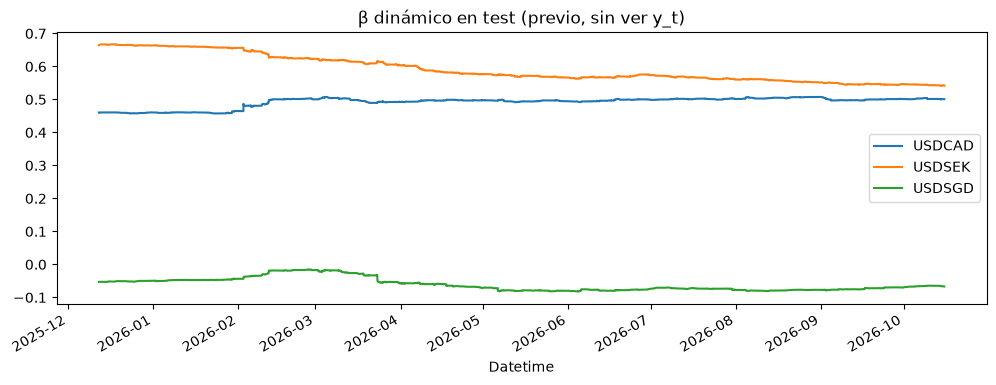

In [10]:
def zscore_with_history(spread_train, spread_test, window=120):
    """Z-score móvil (media y desviación de las últimas `window` horas), usando cola de train para no perder el arranque."""
    full = pd.concat([spread_train.iloc[-window:], spread_test])
    mu, sd = full.rolling(window).mean(), full.rolling(window).std()
    return ((full - mu) / sd).loc[spread_test.index]


def prepare_basket(train_prices, test_prices, basket, k_ar_diff=12, delta=1e-5):
    """Calibra TODO en train; en test solo avanza hora por hora sin reajustar R ni Q."""
    log_train, log_test = np.log(train_prices[basket]), np.log(test_prices[basket])

    vec = np.real(coint_johansen(log_train, det_order=0, k_ar_diff=k_ar_diff).evec[:, 0]).astype(float)
    dep_var = basket[int(np.argmax(np.abs(vec)))]
    x_cols = [c for c in basket if c != dep_var]

    y_tr, y_te = log_train[dep_var].values, log_test[dep_var].values
    X_tr, X_te = log_train[x_cols].values, log_test[x_cols].values
    X_tr_aug = np.column_stack([np.ones(len(X_tr)), X_tr])
    X_te_aug = np.column_stack([np.ones(len(X_te)), X_te])
    n_state = X_tr_aug.shape[1]

    beta_ols = lstsq(X_tr_aug, y_tr, rcond=None)[0]
    R = float((y_tr - X_tr_aug @ beta_ols).var())
    if R <= 0:
        raise ValueError('R degenerada')

    kf = KalmanFilter(
        n_dim_obs=1, n_dim_state=n_state,
        transition_matrices=np.eye(n_state),
        observation_matrices=X_tr_aug.reshape(-1, 1, n_state),
        observation_covariance=R,
        transition_covariance=delta / (1 - delta) * np.eye(n_state),
        initial_state_mean=beta_ols,
        initial_state_covariance=np.eye(n_state) * R,
    )
    means_tr, covs_tr = kf.filter(y_tr)
    prior_tr = np.vstack([beta_ols, means_tr[:-1]])        # β previo en cada hora de train

    cur_mean, cur_cov = means_tr[-1], covs_tr[-1]
    prior_te = []
    for t in range(len(y_te)):
        prior_te.append(cur_mean)                          # β conocido ANTES de ver y_t
        cur_mean, cur_cov = kf.filter_update(
            cur_mean, cur_cov, observation=y_te[t],
            observation_matrix=X_te_aug[t].reshape(1, n_state))
    prior_te = np.array(prior_te)

    beta_static = means_tr[-1]
    return {
        'basket': basket, 'dep_var': dep_var, 'x_cols': x_cols,
        'y_te': y_te, 'X_te': X_te,
        'beta_static': beta_static,
        'beta_x_dyn': prior_te[:, 1:],
        'beta_x_sta': np.tile(beta_static[1:], (len(y_te), 1)),
        'spread_tr_dyn': pd.Series(y_tr - (X_tr_aug * prior_tr).sum(axis=1), index=log_train.index),
        'spread_te_dyn': pd.Series(y_te - (X_te_aug * prior_te).sum(axis=1), index=log_test.index),
        'spread_tr_sta': pd.Series(y_tr - X_tr_aug @ beta_static, index=log_train.index),
        'spread_te_sta': pd.Series(y_te - X_te_aug @ beta_static, index=log_test.index),
    }


prep_main = prepare_basket(train, test, FIXED_BASKET)
print("Dependiente:", prep_main['dep_var'], "| explicativas:", prep_main['x_cols'])
print("β estático (intercepto + pesos):", np.round(prep_main['beta_static'], 4))

pd.DataFrame(prep_main['beta_x_dyn'], index=test.index, columns=prep_main['x_cols']).plot(
    figsize=(12, 4), title="β dinámico en test (previo, sin ver y_t)")
plt.show()

## Fase 4: Reglas de Ejecución y HMM Causal

Mismas reglas (entrada |Z| ≥ 2.0, salida |Z| ≤ 0.5, stop-loss |Z| ≥ 3.5), con dos correcciones: tras un stop-loss no se re-entra hasta que |Z| vuelva a bajar de 2, y el HMM se **entrena solo en `train`** y se decodifica en `test` con el algoritmo forward (causal), no con Viterbi sobre toda la secuencia.

In [11]:
def generate_positions(z, entry=2.0, exit_=0.5, stop=3.5):
    position, blocked, out = 0, False, []
    for v in z.values:
        if blocked and abs(v) < entry:
            blocked = False
        if position == 0:
            if abs(v) >= stop:
                blocked = True                      # dislocación extrema: no entrar
            elif not blocked:
                if v >= entry: position = -1
                elif v <= -entry: position = 1
        elif position == 1:
            if v >= -exit_: position = 0
            elif v <= -stop: position, blocked = 0, True
        elif position == -1:
            if v <= exit_: position = 0
            elif v >= stop: position, blocked = 0, True
        out.append(position)
    return pd.Series(out, index=z.index, name='position')


def hmm_filtered_states(hmm_model, X):
    """Decodificación causal: argmax de P(estado_t | x_1..x_t) con el algoritmo forward."""
    means = hmm_model.means_.flatten()
    stds = np.sqrt(hmm_model.covars_.reshape(len(means), -1)[:, 0])
    A = hmm_model.transmat_
    alpha = hmm_model.startprob_.copy()
    states = np.zeros(len(X), dtype=int)
    for t, x in enumerate(X.flatten()):
        b = norm.pdf(x, loc=means, scale=stds)
        alpha = (alpha * b) if t == 0 else ((alpha @ A) * b)
        s = alpha.sum()
        alpha = alpha / s if s > 0 else np.ones_like(alpha) / len(alpha)
        states[t] = int(np.argmax(alpha))
    return states


def regime_multiplier(spread_train, spread_test, high_vol_mult=0.3, vol_window=24):
    """HMM de 2 estados entrenado SOLO en train, decodificado de forma causal en test."""
    def vol_feature(s):
        return np.log(s.diff().rolling(vol_window).std().replace(0, np.nan))

    ftr = vol_feature(spread_train).dropna()
    full_te = pd.concat([spread_train.iloc[-(vol_window + 1):], spread_test])
    fte = vol_feature(full_te).loc[spread_test.index].dropna()

    hmm = GaussianHMM(n_components=2, covariance_type='diag', n_iter=200, random_state=42)
    hmm.fit(ftr.values.reshape(-1, 1))
    hmm.transmat_ = np.array([[0.98, 0.02], [0.02, 0.98]])      # supuesto de persistencia (igual que antes)
    high = int(np.argmax(hmm.means_.flatten()))

    states = hmm_filtered_states(hmm, fte.values.reshape(-1, 1))
    mult = pd.Series(np.where(states == high, high_vol_mult, 1.0), index=fte.index)
    return mult.reindex(spread_test.index).ffill().fillna(1.0), float((states == high).mean())

## Fase 5: Backtest Corregido

- **P&L con pesos congelados:** el portafolio formado en t es (1 unidad de y, −β_{t−1} de cada x) y gana de t a t+1 exactamente Δy − β·ΔX. Recalibrar β no genera ganancia.
- **Costos sobre todas las patas** (la de y incluida) al cambiar la posición, más el costo de rebalancear pesos mientras se sostiene.
- **Prueba de cordura:** el mismo backtest sobre caminatas aleatorias sin relación debe dar bruto ≈ 0. La versión vieja (diferencia de spread) se calcula en paralelo para ver cuánto fantasma producía sobre puro ruido.

In [12]:
def run_backtest_frozen(y, X_noint, beta_x, position_size, cost_bps=1.0):
    idx = position_size.index
    dy_next = pd.Series(y, index=idx).diff().shift(-1)
    dX_next = pd.DataFrame(X_noint, index=idx).diff().shift(-1)
    pnl_unit_next = dy_next - pd.Series((dX_next.values * beta_x).sum(axis=1), index=idx)
    pnl_gross = (position_size * pnl_unit_next).shift(1).fillna(0)

    legs = pd.Series(1.0 + np.abs(beta_x).sum(axis=1), index=idx)
    trade_cost = position_size.diff().abs().fillna(0) * legs * (cost_bps / 1e4)
    dbeta = pd.Series(np.r_[0.0, np.abs(np.diff(beta_x, axis=0)).sum(axis=1)], index=idx)
    rebalance_cost = position_size.abs() * dbeta * (cost_bps / 1e4)
    costs = trade_cost + rebalance_cost
    return pnl_gross - costs, pnl_gross, costs


def trade_level(positions_raw, pnl):
    """P&L por operación (tramos de posición continua), atribuyendo cada hora a la posición con que se ganó."""
    lagged = positions_raw.shift(1).fillna(0)
    tid = (lagged != lagged.shift()).cumsum()
    is_trade = lagged.groupby(tid).first() != 0
    return pnl.groupby(tid).sum()[is_trade]


def run_strategy(prep, kind, use_hmm=True, entry=2.0, exit_=0.5, stop=3.5, cost_bps=1.0, window=120):
    if kind == 'dinamico':
        s_tr, s_te, beta_x = prep['spread_tr_dyn'], prep['spread_te_dyn'], prep['beta_x_dyn']
    else:
        s_tr, s_te, beta_x = prep['spread_tr_sta'], prep['spread_te_sta'], prep['beta_x_sta']

    z = zscore_with_history(s_tr, s_te, window)
    positions = generate_positions(z.fillna(0), entry, exit_, stop)

    if use_hmm:
        try:
            mult, frac_high = regime_multiplier(s_tr, s_te)
        except Exception:
            mult, frac_high = pd.Series(1.0, index=s_te.index), np.nan
    else:
        mult, frac_high = pd.Series(1.0, index=s_te.index), 0.0
    pos_size = positions * mult

    pnl_net, pnl_gross, costs = run_backtest_frozen(prep['y_te'], prep['X_te'], beta_x, pos_size, cost_bps)
    trades = trade_level(positions, pnl_gross)
    gross_exposure = 1.0 + np.abs(beta_x).sum(axis=1).mean()

    return {
        'bruto': pnl_gross.sum(), 'costos': costs.sum(), 'neto': pnl_net.sum(),
        'bruto_norm': pnl_gross.sum() / gross_exposure, 'neto_norm': pnl_net.sum() / gross_exposure,
        'n_ops': len(trades), 'win_rate_bruto': (trades > 0).mean() if len(trades) else np.nan,
        'pct_activo': (pos_size != 0).mean() * 100, 'pct_alta_vol': frac_high,
        'bruto_spread_viejo': (pos_size.shift(1).fillna(0) * s_te.diff().fillna(0)).sum(),
        'breakeven_bps': pnl_gross.sum() * cost_bps / costs.sum() if costs.sum() > 0 else np.nan,
        'pnl_net_series': pnl_net, 'pnl_gross_series': pnl_gross,
    }

In [13]:
def placebo_check(n_sims=20, seed=0, vol=0.0005):
    rng = np.random.default_rng(seed)
    rows = []
    for i in range(n_sims):
        rets = rng.normal(0, vol, size=(len(data), len(FIXED_BASKET)))
        fake = pd.DataFrame(np.exp(np.cumsum(rets, axis=0)), index=data.index, columns=FIXED_BASKET)
        prep_f = prepare_basket(fake.iloc[:split_idx], fake.iloc[split_idx:], FIXED_BASKET)
        res = run_strategy(prep_f, 'dinamico', use_hmm=False)
        rows.append({'sim': i, 'bruto_congelado': res['bruto'],
                     'bruto_spread_viejo': res['bruto_spread_viejo'], 'n_ops': res['n_ops']})
    return pd.DataFrame(rows)

placebo = placebo_check()
print(placebo[['bruto_congelado', 'bruto_spread_viejo']].describe().loc[['mean', 'std']])
t_new = ttest_1samp(placebo['bruto_congelado'], 0)
t_old = ttest_1samp(placebo['bruto_spread_viejo'], 0)
print(f"\nBacktest corregido sobre ruido puro: media vs 0 -> t={t_new.statistic:.2f}, p={t_new.pvalue:.3f}  (esperado: no significativo)")
print(f"Backtest viejo sobre ruido puro:     media vs 0 -> t={t_old.statistic:.2f}, p={t_old.pvalue:.3f}  (esperado: positivo si había fantasma)")

      bruto_congelado  bruto_spread_viejo
mean        -0.004792            0.209594
std          0.013611            0.018147

Backtest corregido sobre ruido puro: media vs 0 -> t=-1.57, p=0.132  (esperado: no significativo)
Backtest viejo sobre ruido puro:     media vs 0 -> t=51.65, p=0.000  (esperado: positivo si había fantasma)


                         bruto    costos      neto  neto_norm  n_ops  \
dinamico | HMM=False  0.072814  0.087528 -0.014713  -0.006861  204.0   
dinamico | HMM=True   0.050766  0.052703 -0.001937  -0.000903  204.0   
estatico | HMM=False  0.042730  0.024388  0.018341   0.008423   56.0   
estatico | HMM=True  -0.003435  0.019816 -0.023250  -0.010677   56.0   

                      win_rate_bruto  pct_activo  bruto_spread_viejo  \
dinamico | HMM=False        0.691176    8.331730            0.499330   
dinamico | HMM=True         0.691176    8.331730            0.276271   
estatico | HMM=False        0.696429   41.350779            0.042730   
estatico | HMM=True         0.660714   41.350779           -0.003435   

                      breakeven_bps  
dinamico | HMM=False       0.831901  
dinamico | HMM=True        0.963246  
estatico | HMM=False       1.752058  
estatico | HMM=True       -0.173339  

P&L neto según costo por pata:
                      0.25 bps   0.5 bps   1.0 bps   2.0

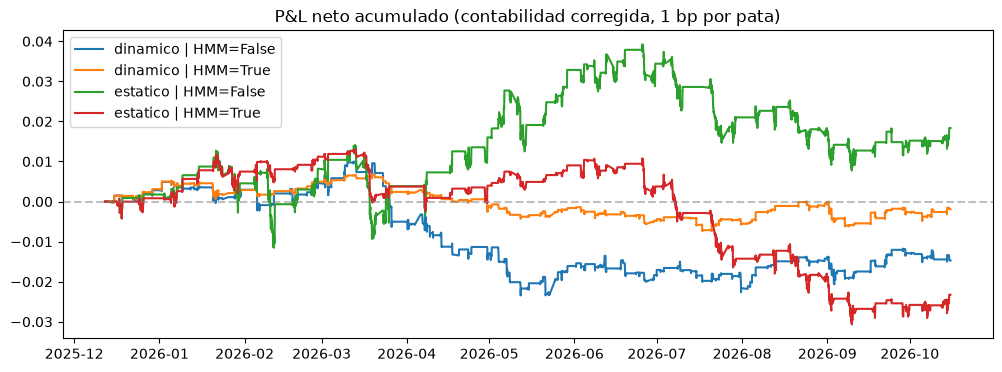

In [14]:
combos = [('dinamico', False), ('dinamico', True), ('estatico', False), ('estatico', True)]
results_main = {f"{k} | HMM={h}": run_strategy(prep_main, k, use_hmm=h) for k, h in combos}

cols = ['bruto', 'costos', 'neto', 'neto_norm', 'n_ops', 'win_rate_bruto',
        'pct_activo', 'bruto_spread_viejo', 'breakeven_bps']
table = pd.DataFrame({name: {m: r[m] for m in cols} for name, r in results_main.items()}).T
print(table)

bps_grid = [0.25, 0.5, 1.0, 2.0, 3.0, 5.0]
sens = pd.DataFrame({name: {f'{b} bps': r['bruto'] - r['costos'] * b for b in bps_grid}
                     for name, r in results_main.items()}).T       # costos calculados a 1 bp -> lineales
print("\nP&L neto según costo por pata:")
print(sens)

plt.figure(figsize=(12, 4))
for name, r in results_main.items():
    plt.plot(r['pnl_net_series'].cumsum(), label=name)
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.legend()
plt.title("P&L neto acumulado (contabilidad corregida, 1 bp por pata)")
plt.show()

## Fase 6: Walk-Forward con la Contabilidad Corregida

Se repite la evaluación sobre 20 ventanas (120 días de entrenamiento, 30 de prueba, paso de 30) con la canasta fija. Cada ventana calibra Kalman, β estático y HMM solo con su propio `train`. Las pruebas de cada ventana no se traslapan, así que se puede contrastar si el bruto medio es distinto de cero.

In [15]:
def generate_walk_forward_windows(df, train_days=120, test_days=30, step_days=30, obs_per_day=24):
    tr_n, te_n, st_n = train_days * obs_per_day, test_days * obs_per_day, step_days * obs_per_day
    windows, start = [], 0
    while start + tr_n + te_n <= len(df):
        windows.append((df.iloc[start:start + tr_n], df.iloc[start + tr_n:start + tr_n + te_n]))
        start += st_n
    return windows

windows = generate_walk_forward_windows(data)
print(f"Ventanas: {len(windows)}")

keys = ['bruto', 'costos', 'neto', 'bruto_norm', 'neto_norm', 'n_ops', 'win_rate_bruto', 'breakeven_bps']
rows = []
for i, (tr, te) in enumerate(windows):
    print(f"Ventana {i}...", end=' ')
    try:
        prep_w = prepare_basket(tr, te, FIXED_BASKET)
    except Exception as e:
        print(f"omitida: {e}")
        continue
    for kind in ['dinamico', 'estatico']:
        for use_hmm in [False, True]:
            r = run_strategy(prep_w, kind, use_hmm=use_hmm)
            rows.append({'window_id': i, 'kind': kind, 'use_hmm': use_hmm, **{k: r[k] for k in keys}})
    print("OK")

wf = pd.DataFrame(rows)

Ventanas: 20
Ventana 0... OK
Ventana 1... OK
Ventana 2... OK
Ventana 3... OK
Ventana 4... OK
Ventana 5... OK
Ventana 6... OK
Ventana 7... OK
Ventana 8... OK
Ventana 9... OK
Ventana 10... OK
Ventana 11... OK
Ventana 12... OK
Ventana 13... OK
Ventana 14... OK
Ventana 15... OK
Ventana 16... OK
Ventana 17... OK
Ventana 18... OK
Ventana 19... OK


In [16]:
summary = wf.groupby(['kind', 'use_hmm']).agg(
    bruto_norm_medio=('bruto_norm', 'mean'),
    neto_norm_medio=('neto_norm', 'mean'),
    ventanas_bruto_pos=('bruto', lambda s: (s > 0).mean()),
    ventanas_neto_pos=('neto', lambda s: (s > 0).mean()),
    win_rate=('win_rate_bruto', 'mean'),
    ops_medias=('n_ops', 'mean'),
    breakeven_bps_mediano=('breakeven_bps', 'median'),
)
print(summary)

print("\nContraste (¿el retorno medio por ventana es distinto de 0?):")
for (kind, use_hmm), g in wf.groupby(['kind', 'use_hmm']):
    tb, tn = ttest_1samp(g['bruto_norm'], 0), ttest_1samp(g['neto_norm'], 0)
    print(f"  {kind:9s} HMM={use_hmm!s:5s} bruto: t={tb.statistic:5.2f} (p={tb.pvalue:.3f}) | neto: t={tn.statistic:5.2f} (p={tn.pvalue:.3f})")

                  bruto_norm_medio  neto_norm_medio  ventanas_bruto_pos  \
kind     use_hmm                                                          
dinamico False            0.001749        -0.003897                0.80   
         True             0.001323        -0.002836                0.85   
estatico False            0.001789         0.000054                0.70   
         True             0.001470        -0.000255                0.75   

                  ventanas_neto_pos  win_rate  ops_medias  \
kind     use_hmm                                            
dinamico False                  0.0  0.649132       28.20   
         True                   0.0  0.649132       28.20   
estatico False                  0.5  0.676566        8.85   
         True                   0.5  0.658348        8.85   

                  breakeven_bps_mediano  
kind     use_hmm                         
dinamico False                 0.430129  
         True                  0.352092  
estatico False

## Conclusión: Backtest Corregido

### Validación del instrumento

- **Etiquetas corregidas.** yfinance devuelve las columnas en orden alfabético; se renombró por ticker. La canasta real validada es USDCAD, USDNOK, USDSEK, USDSGD (Johansen: 1 relación en 5/5 rezagos; EUR/GBP/AUD/NZD: 0/5).
- **Prueba de placebo** (20 caminatas aleatorias independientes): el backtest corregido da bruto medio −0.0048 (p = 0.13, indistinguible de 0); el backtest anterior (diferencia de spread) da +0.2096 (t = 51.65). El método anterior fabricaba ganancia de la nada.

### Resultado (walk-forward de 20 ventanas, canasta fija, 1 bp por pata)

| Variante | Bruto norm. medio | p (bruto) | Neto norm. medio | p (neto) | Ops/ventana | Break-even mediano |
|---|---|---|---|---|---|---|
| Dinámico, sin HMM | 0.00175 | 0.005 | −0.00390 | <0.001 | 28.2 | 0.43 bp |
| Dinámico, con HMM | 0.00132 | 0.004 | −0.00284 | <0.001 | 28.2 | 0.35 bp |
| Estático, sin HMM | 0.00179 | 0.091 | +0.00005 | 0.956 | 8.9 | 1.08 bp |
| Estático, con HMM | 0.00147 | 0.071 | −0.00026 | 0.745 | 8.9 | 0.98 bp |

### Interpretación

1. Existe un borde bruto real pero pequeño (~0.17% por ventana de 30 días, ~2% anual sobre exposición bruta), estadísticamente significativo en la versión dinámica (p = 0.005; p ajustado por Bonferroni sobre 4 variantes = 0.02).
2. El Kalman dinámico no mejora el bruto frente a un β estático (0.00175 vs. 0.00179) pero opera ~3 veces más, y los costos lo vuelven negativo en 20/20 ventanas.
3. El β estático opera cerca del punto de equilibrio (break-even ≈ 1 bp); no hay evidencia de rentabilidad neta (p > 0.7).
4. El filtro HMM no aporta: reduce el bruto, y su efecto sobre el neto del modelo dinámico se debe únicamente a menor exposición.
5. El resultado favorable del corte único (estático sin HMM, neto +0.018) no se sostiene en 20 ventanas (neto medio +0.00005, p = 0.96): es una realización favorable entre cuatro variantes.
6. Es consistente con la auditoría de `Perfiles-Riesgo.ipynb` (bruto ≈ costos).

### Resultados anteriores invalidados

Las conclusiones de `K-D.ipynb`, `Walk-Forward.ipynb` y `Perfiles-Riesgo.ipynb` basadas en P&L (win-rate de 88.7%, Sharpe >10, 20/20 ventanas positivas, "el Kalman dinámico corrige el quiebre", ranking de perfiles, ablation del HMM) no se sostienen con la contabilidad corregida.

### Limitaciones

- Costo uniforme de 1 bp por pata. Para NOK, SEK y SGD el costo real probablemente es varias veces mayor, lo que empeora el neto.
- Calibración en ventanas de 120 días (corta para estimar β).
- La canasta se eligió con datos que se traslapan con parte de las ventanas de prueba (sesgo a favor de la estrategia; refuerza la conclusión de que no hay borde neto).
- Ejecución al cierre de la misma hora en que se calcula la señal.
- Las cotizaciones horarias de pares poco líquidos pueden contener ruido no operable (asincronía, rebote bid-ask), que aparecería como reversión.

### Siguiente paso

Cambiar la razón borde/costo en vez de pelearla en el margen: probar la misma canasta y la misma maquinaria de medición (placebo incluido) a menor frecuencia y con varios años de historia.